# Viken KHATCHERIAN OpenClassrooms — Projet 11 : Reinforcement Learning

# Exercice 1 — Découvrez les blocs de construction de l’apprentissage par renforcement

## Étape 1 — Créer et explorer un environnement

### Objectifs

- Créer l’environnement `CartPole-v1` avec Gymnasium.
- Examiner l’espace d’observation et l’espace d’action.
- Identifier le type et les caractéristiques de chaque espace.
- Générer des exemples d’observations et d’actions aléatoires.

L’environnement CartPole simule un chariot sur lequel est fixé un pendule. L’objectif classique consiste à maintenir le pendule en équilibre en déplaçant le chariot vers la gauche ou vers la droite.

In [36]:
# Importer les bibliothèques
import gymnasium as gym
import stable_baselines3
import matplotlib

print("Gymnasium :", gymnasium.__version__)
print("Stable-Baselines3 :", stable_baselines3.__version__)
print("Matplotlib :", matplotlib.__version__)

Gymnasium : 1.4.0
Stable-Baselines3 : 2.9.0
Matplotlib : 3.10.8


In [37]:
# Création de l'environnement CartPole
env = gym.make("CartPole-v1")

print("Environnement créé :", env.spec.id)

Environnement créé : CartPole-v1


In [38]:
# Exploration de l'espace d'observation
print("Espace d'observation :", env.observation_space)
print("Type de l'espace d'observation :", type(env.observation_space))
print("Nombre de variables observées :", env.observation_space.shape[0])
print("Valeurs minimales :", env.observation_space.low)
print("Valeurs maximales :", env.observation_space.high)

# Exemple d'observation aléatoire
observation_aleatoire = env.observation_space.sample()
print("Exemple d'observation aléatoire :", observation_aleatoire)

Espace d'observation : Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Type de l'espace d'observation : <class 'gymnasium.spaces.box.Box'>
Nombre de variables observées : 4
Valeurs minimales : [-4.8               -inf -0.41887903        -inf]
Valeurs maximales : [4.8               inf 0.41887903        inf]
Exemple d'observation aléatoire : [1.5532401  1.3334358  0.04827223 0.69959694]


### Remarque:
Les bornes -inf et inf affichées pour certaines observations sont normales : Gymnasium ne fixe pas de limites finies pour toutes les variables.

In [39]:
# Exploration de l'espace d'action
print("Espace d'action :", env.action_space)
print("Type de l'espace d'action :", type(env.action_space))
print("Nombre d'actions possibles :", env.action_space.n)

# Exemple d'action aléatoire
action_aleatoire = env.action_space.sample()
print("Exemple d'action aléatoire :", action_aleatoire)

Espace d'action : Discrete(2)
Type de l'espace d'action : <class 'gymnasium.spaces.discrete.Discrete'>
Nombre d'actions possibles : 2
Exemple d'action aléatoire : 1


### Analyse des espaces de CartPole-v1

L’environnement possède un espace d’observation de type `Box`, composé de quatre variables numériques continues décrivant l’état du chariot et du pendule.

Son espace d’action est de type `Discrete(2)`. L’agent dispose de deux actions possibles : déplacer le chariot vers la gauche ou vers la droite.

Cette distinction est fondamentale en apprentissage par renforcement : l’observation décrit ce que l’agent perçoit, tandis que l’action correspond à la décision qu’il peut prendre.

In [40]:
env.close()
print("Environnement fermé proprement.")

Environnement fermé proprement.


## Étape 2 — Politique aléatoire

**Objectif :** faire interagir un agent avec l’environnement `CartPole-v1` pendant 10 épisodes en choisissant une action aléatoire à chaque étape.

Pour chaque épisode, nous allons :

1. Réinitialiser l’environnement avec `env.reset()`.
2. Choisir une action aléatoire avec `env.action_space.sample()`.
3. Appliquer cette action avec `env.step(action)`.
4. Additionner les récompenses obtenues.
5. Arrêter l’épisode lorsque `terminated` ou `truncated` devient vrai.

La récompense totale sera affichée à la fin de chaque épisode.

In [41]:
import gymnasium as gym

# Création de l'environnement
env = gym.make("CartPole-v1")

# Exécution de 10 épisodes
for episode in range(1, 11):

    # Réinitialisation de l'épisode
    observation, info = env.reset()
    total_reward = 0
    terminated = False
    truncated = False

    # Interaction avec l'environnement jusqu'à la fin de l'épisode
    while not terminated and not truncated:

        # Choix d'une action aléatoire
        action = env.action_space.sample()

        # Exécution de l'action
        observation, reward, terminated, truncated, info = env.step(action)

        # Cumul des récompenses
        total_reward += reward

    # Affichage du résultat de l'épisode
    print(f"Épisode {episode:02d} | Récompense totale : {total_reward:.0f}")

# Fermeture de l'environnement
env.close()
print("Environnement fermé proprement.")


Épisode 01 | Récompense totale : 31
Épisode 02 | Récompense totale : 14
Épisode 03 | Récompense totale : 20
Épisode 04 | Récompense totale : 16
Épisode 05 | Récompense totale : 13
Épisode 06 | Récompense totale : 37
Épisode 07 | Récompense totale : 35
Épisode 08 | Récompense totale : 22
Épisode 09 | Récompense totale : 15
Épisode 10 | Récompense totale : 77
Environnement fermé proprement.


### Compréhension des éléments importants:
| Élément | Rôle |
|---|---|
| `env.reset()` | Démarre un nouvel épisode et fournit l'observation initiale. |
| `env.action_space.sample()` | Choisit aléatoirement l'action `0` ou `1`. |
| `env.step(action)` | Applique l'action et renvoie cinq valeurs. |
| `reward` | Récompense reçue après l'action. |
| `total_reward += reward` | Ajoute cette récompense au total de l'épisode. |
| `terminated` | Indique que l'épisode est terminé selon les règles du jeu. |
| `truncated` | Indique que l'épisode a été interrompu, par exemple parce qu'une limite de temps a été atteinte. |
| `env.close()` | Ferme proprement l'environnement. |

### Remarque:
Dans CartPole-v1, la récompense est généralement de +1 à chaque étape où l'épisode continue. La récompense totale correspond donc généralement au nombre d'étapes pendant lesquelles la simulation a duré.

## Complément Exercice 1: visualisation et analyse de CartPole

Les deux premières étapes nous ont permis de découvrir l'environnement CartPole-v1 et de faire interagir un agent utilisant une politique aléatoire.

Nous complétons maintenant cette étude par des visualisations afin de mieux comprendre le comportement du système :

- comparaison des récompenses obtenues lors des dix épisodes pour comparer les performances de l'agent aléatoire d'un épisode à l'autre ;
- évolution des quatre variables physiques pendant un épisode ;
- animation du jeu directement dans le notebook.

Ces visualisations sont complémentaires aux résultats demandés dans les consignes initiales.

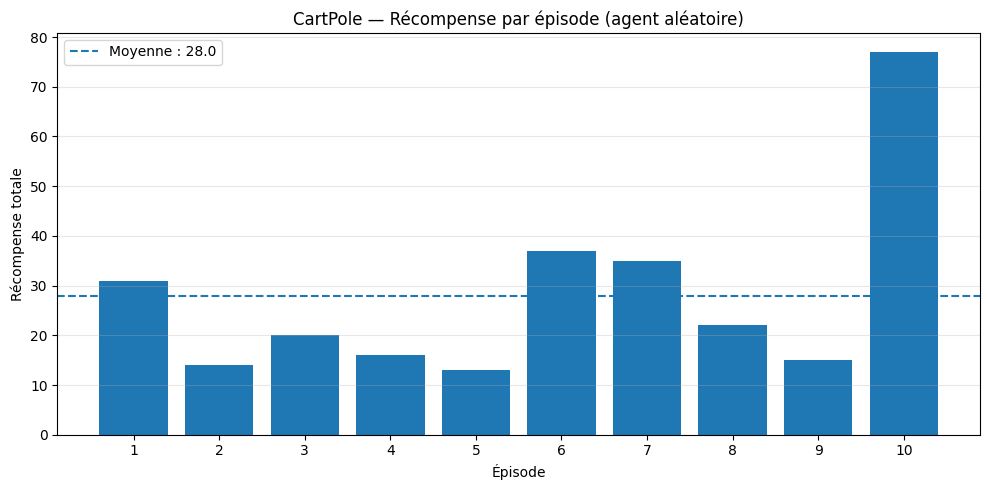

In [42]:
import matplotlib.pyplot as plt

# Récompenses obtenues lors de nos 10 épisodes
rewards = [31, 14, 20, 16, 13, 37, 35, 22, 15, 77]

episodes = range(1, len(rewards) + 1)

plt.figure(figsize=(10, 5))
plt.bar(episodes, rewards)
plt.axhline(
    sum(rewards) / len(rewards),
    linestyle="--",
    label=f"Moyenne : {sum(rewards) / len(rewards):.1f}"
)

plt.title("CartPole — Récompense par épisode (agent aléatoire)")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")
plt.xticks(list(episodes))
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:
plt.savefig(
    "../outputs/figures/cartpole_recompenses_aleatoires.png",
    dpi=150,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

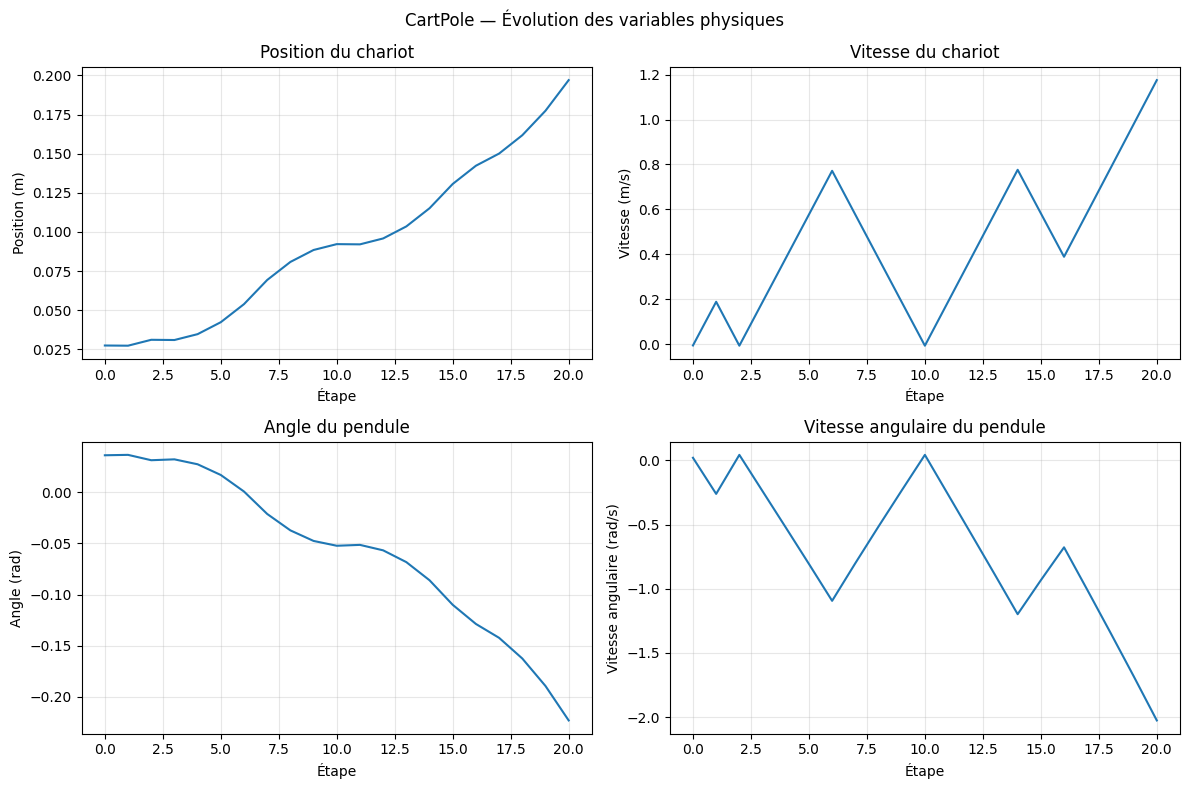

Nombre d'étapes : 20
Dimensions de l'historique : (21, 4)


In [43]:
# Tracé des quatre variables physiques

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

# Création de l'environnement CartPole
env = gym.make("CartPole-v1")

try:
    observation, info = env.reset(seed=42)

    # Enregistrer l'observation initiale
    historique = [observation.copy()]

    terminated = False
    truncated = False

    # Exécuter un épisode avec des actions aléatoires
    while not terminated and not truncated:
        action = env.action_space.sample()

        observation, reward, terminated, truncated, info = env.step(action)

        # Conserver les quatre variables physiques
        historique.append(observation.copy())

    # Convertir l'historique en tableau NumPy
    historique = np.array(historique)

    # Créer l'axe des étapes
    etapes = np.arange(len(historique))

    # Noms et unités des variables
    noms = [
        ("Position du chariot", "Position (m)"),
        ("Vitesse du chariot", "Vitesse (m/s)"),
        ("Angle du pendule", "Angle (rad)"),
        ("Vitesse angulaire du pendule", "Vitesse angulaire (rad/s)")
    ]

    # Créer quatre graphiques
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    for i, ax in enumerate(axes.flat):
        ax.plot(etapes, historique[:, i])
        ax.set_title(noms[i][0])
        ax.set_xlabel("Étape")
        ax.set_ylabel(noms[i][1])
        ax.grid(True, alpha=0.3)

    fig.suptitle("CartPole — Évolution des variables physiques")
    plt.tight_layout()
    plt.show()

    print("Nombre d'étapes :", len(historique) - 1)
    print("Dimensions de l'historique :", historique.shape)

finally:
    env.close()


### Remarques:
- **étape** : L'agent choisit une action, l'environnement l'applique, puis renvoie une nouvelle observation et une récompense.
- **épisode** : Une partie complète, depuis la réinitialisation de l'environnement jusqu'à la fin de la partie (un épisode est donc constitué de plusieurs étapes successives).
- **for** sur les épisodes : combien de parties on veut jouer ;
- **while** dans un épisode : combien d'étapes la partie dure ;
- **reward** : récompense obtenue à une étape ;
- **total_reward** : somme des récompenses pendant tout un épisode.

### Animation de CartPole dans le notebook

Nous enregistrons les images de l'environnement pendant un épisode avec une politique aléatoire, puis nous les assemblons en une animation affichée directement dans JupyterLab.

Cette approche permettra également de comprendre le principe utilisé ultérieurement pour créer une vidéo de démonstration de LunarLander.

In [44]:

import gymnasium as gym
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Création de l'environnement avec capture des images
env = gym.make("CartPole-v1", render_mode="rgb_array")

try:
    observation, info = env.reset(seed=42)

    # Capturer la première image
    frames = [env.render()]

    terminated = False
    truncated = False

    # Exécuter un épisode avec des actions aléatoires
    while not terminated and not truncated:
        action = env.action_space.sample()

        observation, reward, terminated, truncated, info = env.step(action)

        # Enregistrer l'image après chaque action
        frames.append(env.render())

finally:
    env.close()

# Préparer l'affichage de l'animation
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(frames[0])
ax.axis("off")
titre = ax.set_title("CartPole — Agent aléatoire")

def mettre_a_jour(numero):
    image.set_data(frames[numero])
    titre.set_text(f"CartPole — Étape {numero}")
    return [image, titre]

animation = FuncAnimation(
    fig,
    mettre_a_jour,
    frames=len(frames),
    interval=50,
    blit=True
)

plt.close(fig)

display(HTML(animation.to_jshtml()))

print("Nombre d'images capturées :", len(frames))
print("Dimensions d'une image :", frames[0].shape)


Nombre d'images capturées : 68
Dimensions d'une image : (400, 600, 3)


# Exercice 2 — Q-learning avec FrozenLake

## Étape 1 : préparer l'environnement et la Q-table

**Objectif :** créer l'environnement FrozenLake-v1 et initialiser une Q-table avec une ligne par état et une colonne par action possible.

FrozenLake est un environnement à états discrets. La Q-table permettra de stocker une valeur estimée pour chaque couple état-action afin d'aider l'agent à apprendre une stratégie.

In [28]:

import gymnasium as gym
import numpy as np

# 1. Création de l'environnement
env = gym.make("FrozenLake-v1")

# 2. Récupération du nombre d'états et d'actions
nombre_etats = env.observation_space.n
nombre_actions = env.action_space.n

# 3. Initialisation de la Q-table avec des zéros
q_table = np.zeros((nombre_etats, nombre_actions))

# 4. Affichage des informations
print("Environnement :", env.spec.id)
print("Nombre d'états :", nombre_etats)
print("Nombre d'actions :", nombre_actions)
print("Dimensions de la Q-table :", q_table.shape)
print("\nQ-table initialisée :")
print(q_table)

# 5. Fermeture de l'environnement
env.close()


Environnement : FrozenLake-v1
Nombre d'états : 16
Nombre d'actions : 4
Dimensions de la Q-table : (16, 4)

Q-table initialisée :
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


### Remarques:
- **16 lignes : les états**  
  Chaque ligne représente une case de la grille 4 × 4. Les états sont numérotés de 0 à 15.

- **4 colonnes : les actions**  
  Chaque colonne correspond à une action possible : gauche, bas, droite ou haut.

- **Des valeurs initiales égales à zéro**  
  L'agent ne connaît encore aucune stratégie. La Q-table sera mise à jour pendant l'apprentissage.

## Étape 2 — implémenter la boucle de Q-learning

### Principes à comprendre

À chaque étape, l'agent doit choisir entre deux stratégies :

- **Explorer** : choisir une action au hasard pour découvrir son effet.
- **Exploiter** : choisir l'action qui possède la meilleure valeur dans la Q-table pour l'état actuel.

C'est la stratégie *epsilon-greedy*. Au début, l'agent explore souvent ; puis, au fil de l'entraînement, il explore de moins en moins.

La mise à jour de la Q-table suit la formule :

$$
Q(s,a) \leftarrow Q(s,a)+\alpha
\left[
r+\gamma\max_{a'}Q(s',a')-Q(s,a)
\right]
$$

où :

- \(s\) : état actuel ;
- \(a\) : action effectuée ;
- \(r\) : récompense reçue ;
- \(s'\) : nouvel état ;
- \($\alpha$\) (`learning_rate`) : vitesse d'apprentissage ;
- \($\gamma$\) (`discount_factor`) : importance des récompenses futures ;
- \($\epsilon$\) (`epsilon`) : probabilité d'explorer.

**Point de vigilance important :** la mise à jour concerne `q_table[state, action]`, et la valeur future est calculée à partir de `new_state`.

In [45]:

import gymnasium as gym
import numpy as np

# Création de l'environnement
env = gym.make("FrozenLake-v1")

# Initialisation de la Q-table
nombre_etats = env.observation_space.n
nombre_actions = env.action_space.n
q_table = np.zeros((nombre_etats, nombre_actions))

# Hyperparamètres du Q-learning
learning_rate = 0.8
discount_factor = 0.95
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.9995
nombre_episodes = 10_000

# Historique des récompenses
recompenses_episodes = []

# Boucle principale d'entraînement
for episode in range(1, nombre_episodes + 1):

    state, info = env.reset()
    terminated = False
    truncated = False
    total_reward = 0

    # Boucle d'un épisode
    while not terminated and not truncated:

        # 1. Choix de l'action : exploration ou exploitation
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state, :])

        # 2. Exécution de l'action
        new_state, reward, terminated, truncated, info = env.step(action)

        # 3. Valeur Q maximale du nouvel état
        if terminated or truncated:
            max_q_futur = 0
        else:
            max_q_futur = np.max(q_table[new_state, :])

        # 4. Mise à jour de la paire (état, action)
        ancienne_valeur = q_table[state, action]

        nouvelle_valeur = ancienne_valeur + learning_rate * (
            reward
            + discount_factor * max_q_futur
            - ancienne_valeur
        )

        q_table[state, action] = nouvelle_valeur

        # 5. Préparation de l'étape suivante
        state = new_state
        total_reward += reward

    # Enregistrement de la récompense de l'épisode
    recompenses_episodes.append(total_reward)

    # 6. Diminution de l'exploration à la fin de l'épisode
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    # Affichage de la progression
    if episode % 1000 == 0:
        moyenne = np.mean(recompenses_episodes[-1000:])
        print(
            f"Épisode {episode:5d} | "
            f"Epsilon : {epsilon:.3f} | "
            f"Récompense moyenne (1000 épisodes) : {moyenne:.3f}"
        )

env.close()

print("\nEntraînement terminé.")
print("Dimensions de la Q-table :", q_table.shape)
print("\nQ-table apprise :")
print(np.round(q_table, 3))


Épisode  1000 | Epsilon : 0.606 | Récompense moyenne (1000 épisodes) : 0.018
Épisode  2000 | Epsilon : 0.368 | Récompense moyenne (1000 épisodes) : 0.037
Épisode  3000 | Epsilon : 0.223 | Récompense moyenne (1000 épisodes) : 0.069
Épisode  4000 | Epsilon : 0.135 | Récompense moyenne (1000 épisodes) : 0.107
Épisode  5000 | Epsilon : 0.082 | Récompense moyenne (1000 épisodes) : 0.176
Épisode  6000 | Epsilon : 0.050 | Récompense moyenne (1000 épisodes) : 0.222
Épisode  7000 | Epsilon : 0.030 | Récompense moyenne (1000 épisodes) : 0.296
Épisode  8000 | Epsilon : 0.018 | Récompense moyenne (1000 épisodes) : 0.382
Épisode  9000 | Epsilon : 0.011 | Récompense moyenne (1000 épisodes) : 0.442
Épisode 10000 | Epsilon : 0.010 | Récompense moyenne (1000 épisodes) : 0.465

Entraînement terminé.
Dimensions de la Q-table : (16, 4)

Q-table apprise :
[[0.103 0.095 0.034 0.094]
 [0.    0.001 0.006 0.101]
 [0.038 0.003 0.034 0.069]
 [0.002 0.004 0.001 0.043]
 [0.112 0.025 0.093 0.101]
 [0.    0.    0.  

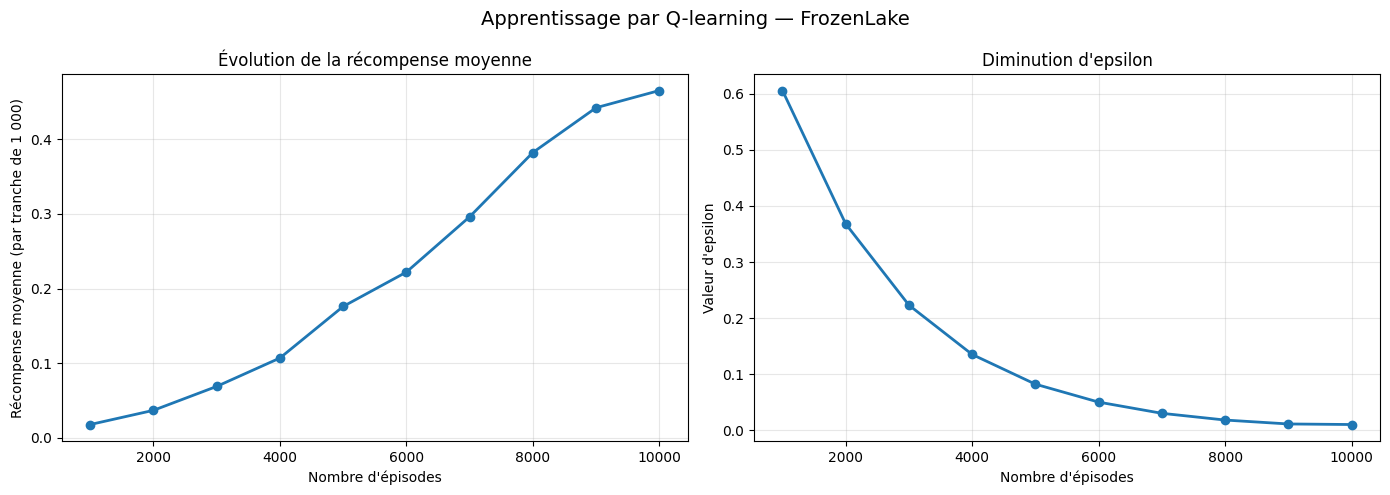

In [46]:

import matplotlib.pyplot as plt

# Résultats de ton entraînement Q-learning
episodes = [
    1000, 2000, 3000, 4000, 5000,
    6000, 7000, 8000, 9000, 10000
]

recompenses_moyennes = [
    0.018, 0.037, 0.069, 0.107, 0.176,
    0.222, 0.296, 0.382, 0.442, 0.465
]

epsilons = [
    0.606, 0.368, 0.223, 0.135, 0.082,
    0.050, 0.030, 0.018, 0.011, 0.010
]

# Création des deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : évolution des récompenses
axes[0].plot(
    episodes,
    recompenses_moyennes,
    marker="o",
    linewidth=2
)
axes[0].set_title("Évolution de la récompense moyenne")
axes[0].set_xlabel("Nombre d'épisodes")
axes[0].set_ylabel("Récompense moyenne (par tranche de 1 000)")
axes[0].grid(True, alpha=0.3)

# Graphique 2 : diminution d'epsilon
axes[1].plot(
    episodes,
    epsilons,
    marker="o",
    linewidth=2
)
axes[1].set_title("Diminution d'epsilon")
axes[1].set_xlabel("Nombre d'épisodes")
axes[1].set_ylabel("Valeur d'epsilon")
axes[1].grid(True, alpha=0.3)

# Ajustement de la mise en page
fig.suptitle("Apprentissage par Q-learning — FrozenLake", fontsize=14)
plt.tight_layout()
plt.show()


**La récompense moyenne augmente:**
  
Elle passe de 0.018 à 0.465. Cela indique que l'agent apprend progressivement à choisir des actions qui le conduisent plus souvent vers l'objectif.

**Epsilon diminue:**
  
Il passe de 0.606 à 0.010. L'agent explore donc de moins en moins et s'appuie davantage sur les valeurs de sa Q-table.

**les deux courbes illustrent les mécanismes complémentaires du Q-learning :**

La diminution de l'exploration et l'amélioration progressive des performances. La récompense moyenne semble toutefois se stabiliser entre les épisodes 9 000 et 10 000 ; cela ne garantit pas que la stratégie soit optimale.

**En effet:**

Entre les épisodes 8 001 et 9 000, la récompense moyenne atteint 0,442, puis 0,465 entre les épisodes 9 001 et 10 000. Cette faible progression suggère une stabilisation des performances de l'agent en fin d'entraînement.

Cette stabilisation ne signifie cependant pas que la stratégie apprise est optimale. En effet, la diminution d'epsilon réduit les possibilités d'exploration de nouvelles actions. L'agent peut donc continuer à exploiter une stratégie qui n'est pas la meilleure possible. De plus, l'environnement FrozenLake est stochastique, car les déplacements peuvent différer des actions choisies.

L'évaluation sur 100 épisodes a donné un taux de réussite de 47 %. Ce résultat montre que l'agent a appris à atteindre l'objectif dans une partie des épisodes, mais que ses performances restent limitées. La stabilisation de la récompense indique donc une progression devenue faible, et non une preuve d'optimalité de la stratégie.

### A comprendre:
| Paramètre | Valeur | Rôle |
|---|---|---|
| `learning_rate` | `0.8` | Importance de la nouvelle information dans la mise à jour. |
| `discount_factor` | `0.95` | Importance accordée aux récompenses futures. |
| `epsilon` | `1.0` au départ | L'agent commence par explorer. |
| `epsilon_min` | `0.01` | Il conserve un faible taux d'exploration. |
| `epsilon_decay` | `0.9995` | Réduit epsilon après chaque épisode. |
| `nombre_episodes` | `10 000` | Nombre de parties d'entraînement. |

| Période d'entraînement | Récompense moyenne | Interprétation |
|---:|---:|---|
| Épisodes 1 à 1 000 | 0,018 | L'agent commence à explorer l'environnement. Il atteint rarement l'objectif et apprend progressivement quelles actions peuvent être utiles. |
| Épisodes 4 001 à 5 000 | 0,176 | L'agent commence à apprendre des stratégies plus efficaces. Il atteint l'objectif plus souvent, même si ses déplacements restent imparfaits. |
| Épisodes 7 001 à 8 000 | 0,382 | Les performances s'améliorent nettement. L'agent semble avoir appris des chemins permettant d'atteindre plus fréquemment la case finale. |
| Épisodes 9 001 à 10 000 | 0,465 | L'agent obtient de meilleurs résultats et semble progresser vers une stratégie plus efficace. La stabilité des performances reste à vérifier sur davantage d'épisodes. ||

- Dans FrozenLake, la récompense est généralement de 1 lorsque l'agent atteint l'objectif et de 0 lorsqu'il n'y parvient pas.
- La récompense moyenne représente donc approximativement la proportion d'épisodes réussis.
- Ainsi, une moyenne de 0.465 signifie qu'environ 46,5 % des épisodes du dernier groupe de 1 000 se sont terminés par une réussite, sous réserve des conditions habituelles de l'environnement. **L'agent apprend progressivement au lieu de rester bloqué à un niveau de performance nul.**

#### Pourquoi epsilon diminue-t-il ?
L'epsilon détermine la fréquence à laquelle l'agent explore l'environnement en choisissant une action aléatoire.

| Épisodes | Epsilon | Comportement |
|---|---:|---|
| Début | 1,000 | L'agent explore presque toujours. |
| 2 000 | 0,368 | Il commence davantage à exploiter ce qu'il a appris. |
| 5 000 | 0,082 | Il choisit généralement l'action qu'il estime la meilleure. |
| 10 000 | 0,010 | L'exploration est devenue très faible. |

Cette diminution est conforme au code :

```python
epsilon = max(epsilon_min, epsilon * epsilon_decay)
```

- Le paramètre epsilon_decay = 0.9995 réduit progressivement l'exploration, tandis que epsilon_min = 0.01 empêche epsilon de descendre en dessous de 1 %.
- **Mais une faible valeur d'epsilon ne garantit pas que la stratégie apprise soit optimale. Si l'agent n'a pas suffisamment exploré certains chemins, il peut conserver une politique imparfaite.**

### Interprétation de la Q-table
Ta Q-table a les dimensions attendues : `(16, 4)`.

- Les 16 lignes représentent les états de FrozenLake.
- Les 4 colonnes représentent les actions possibles.
- Chaque valeur \(Q(s,a)\) estime l'intérêt de choisir l'action \(a\) dans l'état \(s\), en tenant compte des récompenses futures attendues.

Par exemple, la première ligne est :

```python
[0.103, 0.095, 0.034, 0.094]
```
Pour l'état 0, la valeur la plus élevée est `0.103`, dans la colonne d'indice 0. L'agent considère donc l'action 0 comme la meilleure pour cet état.

Voici les correspondances des actions dans FrozenLake :

| Indice | Action |
|---:|---|
| 0 | Gauche |
| 1 | Bas |
| 2 | Droite |
| 3 | Haut |

On peut donc lire la stratégie apprise en choisissant, pour chaque état, l'action dont la valeur Q est maximale.

**D'autres exemples dans la table :**

- État 8 : la valeur maximale est `0.058`, pour l'action 1 (bas).
- État 9 : la valeur maximale est `0.406`, pour l'action 1 (bas).
- État 13 : la valeur maximale est `0.681`, pour l'action 2 (droite).
- État 14 : la valeur maximale est `0.574`, pour l'action 1 (bas).

Les valeurs positives montrent que l'agent a appris que certaines actions peuvent conduire à l'objectif.

Les lignes remplies de zéros, comme celles des états 5 et 7 ne sont pas nécessairement une erreur. Certains états sont des trous ou la case d'arrivée, et les états peu visités peuvent également conserver des valeurs nulles. Dans les états terminaux, aucune action supplémentaire n'est nécessaire.

Il reste une nuance importante : FrozenLake est glissant par défaut (`is_slippery=True`). L'action exécutée peut donc différer de la direction choisie. Cela rend l'environnement stochastique et explique pourquoi l'agent peut échouer même après avoir appris une stratégie utile.

La moyenne de `0.465` indique une progression réelle, mais ne permet pas à elle seule d'affirmer que l'agent a appris la meilleure politique possible. Il faut maintenant évaluer sa stratégie sans exploration, sur plusieurs épisodes distincts de l'entraînement.


## Étape 3 — Evaluer l'agent entraîné
**Important :** cette cellule réutilise la variable q_table obtenue après les 10 000 épisodes d'entraînement. Elle ne réentraîne pas l'agent et ne modifie pas la Q-table.

In [34]:

import gymnasium as gym
import numpy as np

# Création de l'environnement d'évaluation
env_eval = gym.make("FrozenLake-v1")

# Paramètres de l'évaluation
nombre_episodes_test = 100
total_wins = 0

# Boucle d'évaluation
for episode in range(nombre_episodes_test):

    # Réinitialisation de l'environnement
    state, info = env_eval.reset()
    terminated = False
    truncated = False
    total_reward = 0

    # Exécution d'un épisode sans exploration
    while not terminated and not truncated:

        # Exploitation uniquement : choisir la meilleure action connue
        action = int(np.argmax(q_table[state, :]))

        # Exécuter l'action
        new_state, reward, terminated, truncated, info = env_eval.step(action)

        total_reward += reward
        state = new_state

    # Comptabiliser une victoire si l'objectif est atteint
    if total_reward == 1.0:
        total_wins += 1

# Fermeture de l'environnement
env_eval.close()

# Calcul et affichage du taux de réussite
taux_reussite = (total_wins / nombre_episodes_test) * 100

print(f"Nombre d'épisodes évalués : {nombre_episodes_test}")
print(f"Nombre de victoires : {total_wins}")
print(f"Taux de réussite sur {nombre_episodes_test} épisodes : {taux_reussite:.0f}%")


Nombre d'épisodes évalués : 100
Nombre de victoires : 47
Taux de réussite sur 100 épisodes : 47%


### Comprendre les différences avec l'entraînement

#### Aucune exploration

Pendant l'entraînement, l'agent pouvait choisir des actions aléatoires grâce à `epsilon`. Ici, il utilise systématiquement `np.argmax(q_table[state, :])`.

#### Aucune mise à jour de la Q-table

Nous ne calculons aucune `nouvelle_valeur` et n'affectons aucune valeur à `q_table`. Nous mesurons simplement les performances de la stratégie apprise.

#### Réinitialisation à chaque épisode

`env_eval.reset()` replace l'agent au point de départ pour chaque nouvel essai.

#### Calcul du taux de réussite

Le compteur `total_wins` augmente uniquement lorsqu'un épisode rapporte `1.0`, ce qui correspond à l'atteinte de l'objectif dans FrozenLake.

### Analyse des résultats:
L'agent a atteint l'objectif dans 47 épisodes et échoué dans 53 autres.

Dans FrozenLake, l'objectif est d'atteindre la case finale sans tomber dans un trou. Par défaut, l'environnement est glissant : les déplacements sont aléatoires. Même lorsque l'agent choisit une action adaptée, il ne se déplace pas forcément dans la direction souhaitée.

Un taux de réussite de 47 % ne signifie donc pas que le code est incorrect. Il signifie que la stratégie apprise réussit dans une partie des situations, mais pas encore de manière fiable.

#### résultats cohérents avec l'entraînement ?

Rappel des résultats obtenus à l'entraînement :

| Episodes atteints | Récompense moyenne enregistrée |
|---|---:|
| 1 000 | 0,018 |
| 5 000 | 0,176 |
| 7 000 | 0,296 |
| 8 000 | 0,382 |
|10 000 | 0.465 |
| Évaluation séparée de l'entraînement | 0,470 |

La dernière récompense moyenne de l'entraînement était de `0.465` après 10000 épisodes atteints, et l'évaluation a donné `0.470`.

Ces résultats sont très proches. C'est cohérent avec le comportement attendu : dans les deux cas, l'agent utilise une stratégie issue de la même Q-table et l'environnement reste aléatoire.

Il faut néanmoins garder une nuance : pendant l'entraînement, la récompense moyenne incluait encore un peu d'exploration, tandis que l'évaluation utilise exclusivement la meilleure action estimée.

#### Pourquoi le résultat change-t-il lorsque la cellule de code est relancée ?

C'est normal, pour deux raisons.

##### 1. FrozenLake est un environnement aléatoire

À chaque appel à `env_eval.reset()`, l'épisode recommence. Comme `FrozenLake-v1` utilise par défaut `is_slippery=True`, les mouvements ne suivent pas toujours la direction choisie. Une même stratégie peut donc réussir un épisode et échouer au suivant.

##### 2. 100 épisodes testés à chaque exécution

Cent essais constituent un échantillon limité. Selon les trajectoires tirées au hasard, on peut obtenir, par exemple, 42 %, 47 % ou 53 % de réussite. Ces chiffres illustrent une variation possible, pas des résultats qui sont nécessairement à observer.

#### Est-ce que la Q-table change quand on relance l'évaluation ?

Non, car on utilise :
```python
action = int(np.argmax(q_table[state, :]))
```
Mais on ne modifie jamais q_table.
La stratégie apprise reste donc la même. 
Ce sont les trajectoires de l'environnement qui changent.

#### Comment rendre l'évaluation davantage fiable ?
Pour obtenir une estimation moins sensible au hasard, on peut augmenter le nombre d'épisodes, par exemple à 1 000. On n'a pas besoin de réentraîner l'agent.
On indique dans le code:
```python
nombre_episodes_test = 1000 au lieu de nombre_episodes_test = 100
```
Le résultat devrait être plus stable, même s'il ne sera pas nécessairement identique à chaque exécution.

### Évaluation du Q-learning sur FrozenLake

L'agent entraîné pendant 10 000 épisodes a obtenu un taux de réussite de **47 % sur 100 épisodes d'évaluation**, soit 47 victoires.

Ce résultat montre que l'agent a appris une stratégie permettant d'atteindre l'objectif dans une partie des épisodes. Les performances restent toutefois limitées, car FrozenLake est glissant par défaut : les déplacements peuvent différer des actions choisies.

Le taux de réussite varie d'une exécution à l'autre en raison de l'aléa de l'environnement et du nombre limité d'épisodes évalués. La Q-table, elle, reste inchangée pendant l'évaluation.

L'étape d'évaluation est réalisée conformément aux consignes : l'agent exploite exclusivement la Q-table apprise, les victoires sont comptabilisées et le taux de réussite est calculé.

# Exercice 3 — Remplacez la Q-table par un cerveau neuronal (DQN)

## Étape 1 — Définir le réseau de neurones et le Replay Buffer (Manuel)

### Classe `DQN` — le cerveau de l’agent

Elle reçoit un état de l’environnement et estime la valeur de chaque action possible. Pour CartPole, elle reçoit 4 valeurs et renvoie 2 valeurs, une par action.

### Classe `ReplayBuffer` — la mémoire de l’agent

Elle conserve les expériences passées (état, action, récompense, nouvel état), puis permet d’en tirer un échantillon aléatoire pour entraîner le réseau.





In [47]:
# import des bibliothèques
import random
from collections import deque

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

In [49]:
# créer la classe DQN

class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x

### Comment fonctionne ce réseau ?

- **Entrée : 4 valeurs**
  - Position
  - Vitesse
  - Angle
  - Vitesse angulaire

- **Couche cachée : 128 neurones**
  - Fonction d'activation : ReLU

- **Couche cachée : 128 neurones**
  - Fonction d'activation : ReLU

- **Sortie : 2 valeurs Q**
  - Action 0 : gauche
  - Action 1 : droite

Les valeurs Q sont des estimations de l’intérêt de chaque action. Le réseau ne choisit pas lui-même l’action : l’agent utilisera ensuite ces valeurs pour décider.

In [50]:
# créer la classe ReplayBuffer

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        experience = (state, action, reward, next_state, done)
        self.buffer.append(experience)

    def sample(self, batch_size):
        return random.sample(self.buffer, batch_size)

    def __len__(self):
        return len(self.buffer)


In [51]:
# Instancier le réseau et afficher son architecture

env = gym.make("CartPole-v1")

input_dim = env.observation_space.shape[0]
output_dim = env.action_space.n

dqn = DQN(input_dim, output_dim)
replay_buffer = ReplayBuffer(capacity=10_000)

print("Nombre de valeurs en entrée :", input_dim)
print("Nombre d'actions possibles :", output_dim)
print("\nArchitecture du réseau DQN :")
print(dqn)

print("\nCapacité du Replay Buffer :", replay_buffer.buffer.maxlen)
print("Nombre d'expériences stockées :", len(replay_buffer))

env.close()


Nombre de valeurs en entrée : 4
Nombre d'actions possibles : 2

Architecture du réseau DQN :
DQN(
  (fc1): Linear(in_features=4, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=2, bias=True)
)

Capacité du Replay Buffer : 10000
Nombre d'expériences stockées : 0


In [52]:
# Confirmer par un test que le réseau reçoit bien un état et produit deux valeurs Q
# Créer un état fictif contenant les 4 observations de CartPole
etat_test = torch.zeros(1, 4)

# Faire passer cet état dans le réseau
valeurs_q = dqn(etat_test)

print("Dimensions de l'état :", etat_test.shape)
print("Dimensions des valeurs Q :", valeurs_q.shape)
print("Valeurs Q :", valeurs_q.detach().numpy())

Dimensions de l'état : torch.Size([1, 4])
Dimensions des valeurs Q : torch.Size([1, 2])
Valeurs Q : [[-0.07616513 -0.05205463]]


## Etape 2 - Comprendre les éléments de la boucle

Rôle des principaux composants :

### `policy_net` — le réseau qui apprend

Il estime les valeurs Q des actions à partir de l'état actuel. Ses poids sont ajustés pendant l'entraînement.

### `target_net` — le réseau cible

Il fournit une estimation plus stable des valeurs Q des états suivants. Ses poids sont périodiquement copiés depuis `policy_net`.

### `ReplayBuffer` — la mémoire

Il conserve les expériences de l'agent et fournit des lots aléatoires (*batches*) pour entraîner le réseau.

## 2. Le principe de l'apprentissage

La fonction `optimize_model()` est le cœur de l'apprentissage. Elle compare deux quantités :

- **Valeur Q prédite :** ce que `policy_net` estime pour l'action réellement effectuée.
- **Valeur Q cible :** la récompense obtenue, à laquelle on ajoute la valeur estimée de l'état suivant par `target_net`, si l'épisode n'est pas terminé.

La formule simplifiée est :

$$
Q_{\text{cible}} = r + \gamma \max_{a'} Q_{\text{target}}(s', a')
$$

où :

- \(r\) est la récompense obtenue ;
- \(s'\) est le nouvel état ;
- \(a'\) représente une action possible dans le nouvel état ;
- \($\gamma$\) est le facteur d'actualisation, qui détermine l'importance des récompenses futures ;
- \($Q_{\text{target}}(s', a')$\) est la valeur estimée par le réseau cible pour le nouvel état et une action possible.

Si l'épisode est terminé, la valeur future est nulle. La formule devient alors :

$$
Q_{\text{cible}} = r
$$

Le réseau apprend en réduisant l'écart entre sa prédiction et cette cible, grâce à une fonction de perte et à un optimiseur PyTorch.

### Préparation de l'entraînement
La boucle d’entraînement utilisera deux réseaux :

- policy_net : le réseau qui apprend ;
- target_net : une copie du réseau qui sert à calculer les valeurs Q cibles.

Elle utilisera aussi le Replay Buffer créé à l’étape 1, mais nous allons en créer une nouvelle instance pour l’entraînement.

In [53]:
# créer les paramètres et initialiser les réseaux

# 1. Environnement
env = gym.make("CartPole-v1")

# 2. Dimensions de l'environnement
input_dim = env.observation_space.shape[0]
output_dim = env.action_space.n

# 3. Choix du matériel : GPU si disponible, sinon CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 4. Paramètres de l'entraînement
nombre_episodes = 500
batch_size = 128
gamma = 0.99
learning_rate = 0.001

epsilon_debut = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

capacite_buffer = 20_000
frequence_maj_target = 10

# 5. Création du réseau qui apprend
policy_net = DQN(input_dim, output_dim).to(device)

# 6. Création du réseau cible
target_net = DQN(input_dim, output_dim).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

# 7. Optimiseur du réseau qui apprend
optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=learning_rate
)

# 8. Mémoire des expériences
replay_buffer = ReplayBuffer(capacite_buffer)

# 9. Historique des récompenses
recompenses_episodes = []

print("Environnement :", env.spec.id)
print("Matériel utilisé :", device)
print("Nombre d'épisodes :", nombre_episodes)
print("Batch size :", batch_size)
print("Réseau policy_net :")
print(policy_net)
print("Réseau target_net initialisé avec les mêmes poids.")
print("Capacité du Replay Buffer :", capacite_buffer)


Environnement : CartPole-v1
Matériel utilisé : cuda
Nombre d'épisodes : 500
Batch size : 128
Réseau policy_net :
DQN(
  (fc1): Linear(in_features=4, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=2, bias=True)
)
Réseau target_net initialisé avec les mêmes poids.
Capacité du Replay Buffer : 20000


### Comprendre les paramètres principaux

| Paramètre | Rôle |
|---|---|
| `nombre_episodes = 500` | Nombre de parties jouées pendant l’apprentissage. |
| `batch_size = 128` | Nombre d’expériences utilisées lors d’une optimisation. |
| `gamma = 0.99` | Importance accordée aux récompenses futures. |
| `learning_rate = 0.001` | Vitesse d’ajustement des poids du réseau. |
| `epsilon_debut = 1.0` | Au départ, l’agent explore en choisissant des actions aléatoires. |
| `epsilon_min = 0.05` | L’agent conserve au minimum 5 % d’exploration. |
| `frequence_maj_target = 10` | Le réseau cible sera synchronisé tous les 10 épisodes. |

Ces valeurs sont un point de départ raisonnable, pas une garantie d’atteindre une récompense moyenne de 200. Nous pourrons analyser les résultats après l’entraînement.

### Pourquoi deux réseaux ?

Au début, `policy_net` et `target_net` possèdent les mêmes poids. Ensuite, seul `policy_net` est optimisé à chaque mise à jour. 

Périodiquement, nous copierons ses poids dans `target_net` pour stabiliser les cibles d’apprentissage.

### Création de la fonction optimize_model()
Cette fonction va prélever un échantillon d’expériences dans le Replay Buffer, calculer les valeurs Q prédites et les valeurs Q cibles, puis ajuster les poids du réseau policy_net.

In [54]:

def optimize_model():
    # Attendre d'avoir assez d'expériences pour constituer un batch
    if len(replay_buffer) < batch_size:
        return None

    # 1. Prélever un batch aléatoire d'expériences
    transitions = replay_buffer.sample(batch_size)

    states, actions, rewards, next_states, dones = zip(*transitions)

    # 2. Convertir les expériences en tenseurs PyTorch
    states = torch.tensor(
        np.array(states), dtype=torch.float32, device=device
    )
    actions = torch.tensor(
        actions, dtype=torch.long, device=device
    ).unsqueeze(1)
    rewards = torch.tensor(
        rewards, dtype=torch.float32, device=device
    ).unsqueeze(1)
    next_states = torch.tensor(
        np.array(next_states), dtype=torch.float32, device=device
    )
    dones = torch.tensor(
        dones, dtype=torch.float32, device=device
    ).unsqueeze(1)

    # 3. Calculer les Q-values prédites pour les actions réellement choisies
    q_values = policy_net(states).gather(1, actions)

    # 4. Calculer les Q-values cibles pour les nouveaux états
    with torch.no_grad():
        next_q_values = target_net(next_states).max(1)[0].unsqueeze(1)

        # Si l'épisode est terminé, aucune récompense future n'est ajoutée
        target_q_values = rewards + gamma * next_q_values * (1 - dones)

    # 5. Calculer l'erreur entre prédictions et valeurs cibles
    loss = F.smooth_l1_loss(q_values, target_q_values)

    # 6. Mettre à jour les poids du réseau policy_net
    optimizer.zero_grad()
    loss.backward()

    # Limiter les gradients pour stabiliser l'apprentissage
    torch.nn.utils.clip_grad_norm_(policy_net.parameters(), 10.0)

    optimizer.step()

    return loss.item()


`policy_net(states).gather(1, actions)` récupère la valeur Q prédite pour l’action effectivement choisie.

1. `target_net(next_states).max(1)[0]` récupère la valeur Q maximale estimée pour chaque nouvel état.
2. `rewards + gamma * next_q_values * (1 - dones)` calcule la cible de Bellman, sans valeur future si l’épisode est terminé.
3. `F.smooth_l1_loss(...)` mesure l’écart entre les valeurs prédites et les valeurs cibles.
4. `optimizer.step()` ajuste les poids de `policy_net`.

In [55]:
# Ajout de la boucle d'entraînement

# Exploration initiale
epsilon = epsilon_debut

# Compteur pour les optimisations du réseau
nombre_optimisations = 0

for episode in range(1, nombre_episodes + 1):
    # Réinitialiser l'environnement au début de chaque épisode
    state, info = env.reset()
    total_reward = 0
    terminated = False
    truncated = False

    while not terminated and not truncated:

        # 1. Sélection de l'action : exploration ou exploitation
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            state_tensor = torch.tensor(
                state, dtype=torch.float32, device=device
            ).unsqueeze(0)

            with torch.no_grad():
                action = policy_net(state_tensor).argmax(dim=1).item()

        # 2. Exécuter l'action dans l'environnement
        next_state, reward, terminated, truncated, info = env.step(action)

        # 3. Enregistrer la transition dans le Replay Buffer
        done = terminated or truncated
        replay_buffer.push(
            state, action, reward, next_state, done
        )

        # 4. Passer au nouvel état et cumuler la récompense
        state = next_state
        total_reward += reward

        # 5. Optimiser le réseau à partir d'un batch d'expériences
        loss = optimize_model()

        if loss is not None:
            nombre_optimisations += 1

    # 6. Réduire progressivement l'exploration
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    # 7. Synchroniser périodiquement le réseau cible
    if episode % frequence_maj_target == 0:
        target_net.load_state_dict(policy_net.state_dict())

    # 8. Conserver la récompense de cet épisode
    recompenses_episodes.append(total_reward)

    # 9. Afficher la progression tous les 50 épisodes
    if episode % 50 == 0:
        moyenne = np.mean(recompenses_episodes[-50:])
        print(
            f"Épisode {episode:3d} | "
            f"Récompense moyenne (50 épisodes) : {moyenne:.2f} | "
            f"Epsilon : {epsilon:.3f}"
        )

env.close()

print("\nEntraînement terminé.")
print("Nombre total d'optimisations :", nombre_optimisations)
print("Nombre d'épisodes enregistrés :", len(recompenses_episodes))


Épisode  50 | Récompense moyenne (50 épisodes) : 24.00 | Epsilon : 0.778
Épisode 100 | Récompense moyenne (50 épisodes) : 42.12 | Epsilon : 0.606
Épisode 150 | Récompense moyenne (50 épisodes) : 54.90 | Epsilon : 0.471
Épisode 200 | Récompense moyenne (50 épisodes) : 37.56 | Epsilon : 0.367
Épisode 250 | Récompense moyenne (50 épisodes) : 38.14 | Epsilon : 0.286
Épisode 300 | Récompense moyenne (50 épisodes) : 48.10 | Epsilon : 0.222
Épisode 350 | Récompense moyenne (50 épisodes) : 35.20 | Epsilon : 0.173
Épisode 400 | Récompense moyenne (50 épisodes) : 72.64 | Epsilon : 0.135
Épisode 450 | Récompense moyenne (50 épisodes) : 105.06 | Epsilon : 0.105
Épisode 500 | Récompense moyenne (50 épisodes) : 200.20 | Epsilon : 0.082

Entraînement terminé.
Nombre total d'optimisations : 32769
Nombre d'épisodes enregistrés : 500


1. `epsilon` diminue au fil des épisodes : l'agent explore moins et exploite davantage ce qu'il a appris.
2. `target_net.load_state_dict(policy_net.state_dict())` est la ligne qui synchronise les deux réseaux.
3. Le buffer contient les transitions accumulées au fil de l'entraînement.
4. `optimize_model()` ne commence à entraîner le réseau que lorsque le buffer contient au moins `batch_size`, soit 128 expériences.

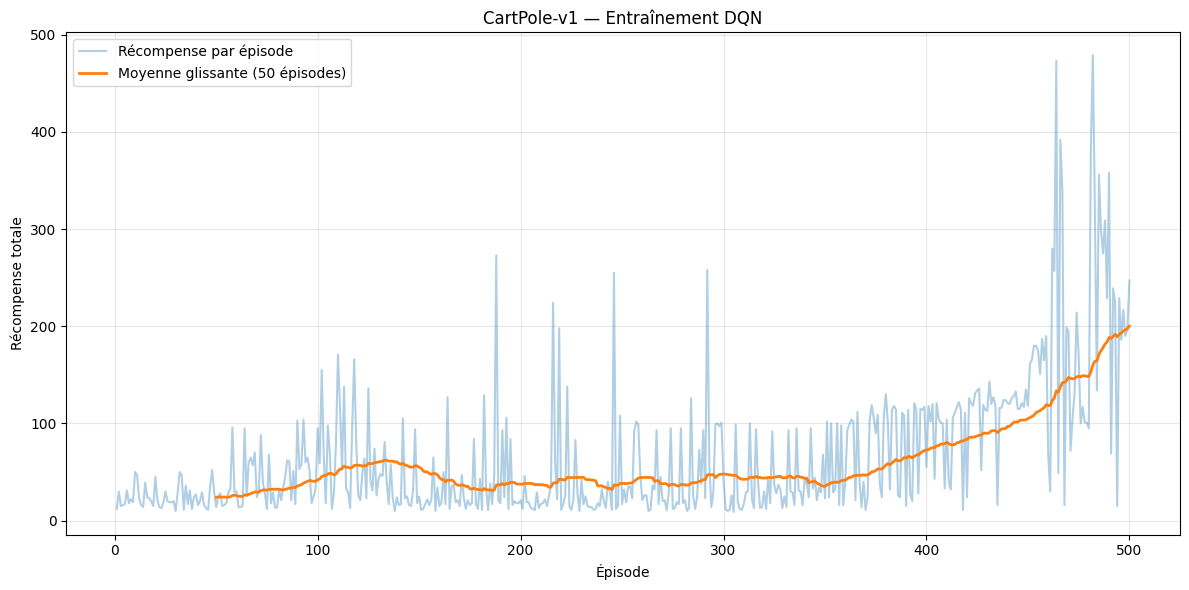

Récompense moyenne des 50 derniers épisodes : 200.20


In [56]:
# Tracer la courbe des récompenses par épisode utilisant la liste recompenses_episodes créée pendant l'entraînement

import matplotlib.pyplot as plt
import numpy as np

# Numéro de chaque épisode
episodes = range(1, len(recompenses_episodes) + 1)

# Calcul d'une moyenne glissante sur 50 épisodes
fenetre = 50
moyenne_glissante = np.convolve(
    recompenses_episodes,
    np.ones(fenetre) / fenetre,
    mode="valid"
)

episodes_moyenne = range(fenetre, len(recompenses_episodes) + 1)

# Création du graphique
plt.figure(figsize=(12, 6))

# Récompense de chaque épisode
plt.plot(
    episodes,
    recompenses_episodes,
    alpha=0.35,
    label="Récompense par épisode"
)

# Moyenne glissante
plt.plot(
    episodes_moyenne,
    moyenne_glissante,
    linewidth=2,
    label="Moyenne glissante (50 épisodes)"
)

plt.title("CartPole-v1 — Entraînement DQN")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(
    f"Récompense moyenne des 50 derniers épisodes : "
    f"{np.mean(recompenses_episodes[-50:]):.2f}"
)



- Moyenne glissante sur 50 épisodes : elle permet de mieux voir la tendance générale de l’apprentissage.
- Une tendance ascendante : elle indique généralement que l’agent apprend à maintenir le pendule en équilibre plus longtemps.
- Attention : ce graphique représente les récompenses obtenues pendant l’entraînement, avec une part d’exploration aléatoire. Il ne constitue pas encore une évaluation indépendante des performances de l’agent.

L'agent DQN obtient une moyenne de 200,20 points sur les 50 derniers épisodes d’entraînement. C’est un très bon signe, mais cela ne prouve pas encore qu’il sait réussir régulièrement, pour trois raisons.

#### Pendant l'entraînement, l'agent explore encore

Dans notre boucle, nous utilisons une stratégie appelée epsilon-greedy :

```python
if random.random() < epsilon:
    action = env.action_space.sample()
else:
    action = policy_net(state_tensor).argmax(dim=1).item()
```
L’agent a deux possibilités :

- **Explorer :** choisir une action au hasard.
- **Exploiter :** choisir l’action que le réseau DQN estime la meilleure.

À la fin des 500 épisodes on avait epsilon=0.082

Cela signifie que l’agent choisit encore une action aléatoire environ 8,2 % du temps, selon cette stratégie. Il utilise le réseau pour choisir son action environ 91,8 % du temps.

Cette exploration est utile pendant l’apprentissage, mais elle peut faire baisser les récompenses. Pour évaluer ce que le réseau a réellement appris, nous voulons tester l’agent sans ces choix aléatoires.

#### Une moyenne de 200,20 peut masquer des épisodes très différents

Supposons que l'agent obtienne les récompenses suivantes sur cinq épisodes :

| Épisode | Récompense |
|--------:|-----------:|
| 1       | 300        |
| 2       | 280        |
| 3       | 250        |
| 4       | 50         |
| 5       | 121        |

La moyenne est de 200,2, mais l’agent n’a pas réussi à maintenir le pendule aussi longtemps à chaque fois.

C’est un exemple fictif, pas le résultat de l'entraînement. Il illustre pourquoi une moyenne seule ne suffit pas.

Pour mieux comprendre la stabilité, on peut examiner :

- La moyenne des récompenses ;
- L’écart-type, qui mesure leur dispersion ;
- Le nombre d’épisodes atteignant un objectif donné.

#### L’environnement comporte une part de variabilité

À chaque nouvel épisode, CartPole démarre avec un état initial légèrement différent. Même avec un réseau identique et sans exploration aléatoire, les récompenses peuvent donc varier.

Une évaluation sur plusieurs épisodes permet de déterminer si les performances sont généralement bonnes, ou si la moyenne élevée provient seulement de quelques épisodes particulièrement réussis.

Nous pouvons réaliser une évaluation sur 100 épisodes, sans exploration aléatoire et sans modifier les poids du réseau.
Le principe est simple :
1. Conserver le policy_net entraîné.
2. Désactiver la sélection aléatoire et choisir systématiquement l'action ayant la valeur Q la plus élevée.
3. Exécuter 100 épisodes indépendants.
4. Calculer la moyenne, l'écart-type et le taux d'épisodes atteignant 200 points.

In [58]:
env_eval = gym.make("CartPole-v1")

nombre_episodes_test = 100
recompenses_test = []

policy_net.eval()

for episode in range(nombre_episodes_test):
    state, info = env_eval.reset()
    total_reward = 0
    terminated = False
    truncated = False

    while not terminated and not truncated:
        state_tensor = torch.tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            action = policy_net(state_tensor).argmax(dim=1).item()

        state, reward, terminated, truncated, info = env_eval.step(action)
        total_reward += reward

    recompenses_test.append(total_reward)

env_eval.close()

moyenne_test = np.mean(recompenses_test)
ecart_type_test = np.std(recompenses_test)
taux_200 = np.mean(np.array(recompenses_test) >= 200) * 100

print("Nombre d'épisodes testés :", nombre_episodes_test)
print(f"Récompense moyenne : {moyenne_test:.2f}")
print(f"Écart-type : {ecart_type_test:.2f}")
print(f"Épisodes avec une récompense >= 200 : {taux_200:.1f} %")


Nombre d'épisodes testés : 100
Récompense moyenne : 231.62
Écart-type : 5.98
Épisodes avec une récompense >= 200 : 100.0 %


L'agent DQN a été entraîné pendant 500 épisodes sur l'environnement CartPole-v1. La récompense moyenne des 50 derniers épisodes d'entraînement atteint 200,20, contre 24,00 pour les 50 premiers épisodes. Cette progression indique que l'agent a appris à mieux contrôler le pendule.

Une évaluation distincte a ensuite été réalisée sur 100 épisodes, sans exploration aléatoire. Les résultats obtenus sont les suivants :

- **Récompense moyenne :** 231,62.
- **Écart-type des récompenses :** 5,98.
- **Proportion d'épisodes obtenant une récompense supérieure ou égale à 200 :** 100 %.

La récompense moyenne élevée et le faible écart-type indiquent que les performances sont bonnes et relativement régulières sur les épisodes testés. Tous les épisodes évalués ont atteint le seuil de 200 points.

Cette évaluation confirme que le réseau DQN a appris une stratégie efficace pour l'environnement CartPole-v1. Ces résultats restent toutefois limités aux 100 épisodes testés et à cet environnement.

L'exercice a permis de mettre en œuvre un réseau de neurones DQN, un Replay Buffer, une fonction d'optimisation et un réseau cible, puis d'observer et d'évaluer l'apprentissage de l'agent.

## Etape 3 - Entraîner et évaluer avec Stable-Baselines3

La différence avec l’étape 2 est importante : nous avions programmé nous-mêmes le réseau, le Replay Buffer et la boucle d’apprentissage. Ici, Stable-Baselines3 fournit déjà l’implémentation du DQN. Nous allons donc l’utiliser plutôt que de réécrire son fonctionnement interne.

### Plan de l’étape 3

1. **Préparer les imports et l’environnement**

   Vérifier Stable-Baselines3 et créer CartPole-v1.

2. **Créer le modèle DQN**

   Utiliser `MlpPolicy` et configurer TensorBoard comme demandé.

3. **Entraîner le modèle**

   Effectuer 25 000 interactions avec l’environnement.

4. **Évaluer sur 100 épisodes**

   Calculer la récompense moyenne et l’écart-type avec `evaluate_policy`.

5. **Sauvegarder le modèle**

   Créer le fichier `dqn_cartpole.zip` dans le dépôt du projet.

In [59]:
# Préparer les imports et l'environnement

import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy

# Création de l'environnement CartPole
env = gym.make("CartPole-v1")

print("Stable-Baselines3 : importé avec succès")
print("Environnement :", env.spec.id)
print("Nombre d'observations :", env.observation_space.shape[0])
print("Nombre d'actions :", env.action_space.n)


Stable-Baselines3 : importé avec succès
Environnement : CartPole-v1
Nombre d'observations : 4
Nombre d'actions : 2


In [60]:
# Création du modèle DQN avec Stable-Baselines3
model = DQN(
    "MlpPolicy",
    env,
    verbose=1,
    tensorboard_log="./logs/"
)

print("\nModèle DQN créé avec succès.")
print("Type du modèle :", type(model).__name__)
print("Politique utilisée :", type(model.policy).__name__)


Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.

Modèle DQN créé avec succès.
Type du modèle : DQN
Politique utilisée : DQNPolicy


- `MlpPolicy` : utilise un réseau de neurones de type perceptron multicouche pour traiter les observations de CartPole.
- `env` : indique au modèle l’environnement dans lequel il apprendra.
- `verbose=1` : affiche des informations pendant l’entraînement.
- `tensorboard_log="./logs/"` : indique le dossier où enregistrer les journaux d’entraînement destinés à TensorBoard.

In [62]:
# Entraînement du modèle DQN
total_timesteps = 25_000

model.learn(
    total_timesteps=total_timesteps
)

print("\nEntraînement terminé.")
print("Nombre d'interactions demandées :", total_timesteps)


Logging to ./logs/DQN_2
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 15.2     |
|    ep_rew_mean      | 15.2     |
|    exploration_rate | 0.977    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 18130    |
|    time_elapsed     | 0        |
|    total_timesteps  | 61       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 22.4     |
|    ep_rew_mean      | 22.4     |
|    exploration_rate | 0.932    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 4260     |
|    time_elapsed     | 0        |
|    total_timesteps  | 179      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.489    |
|    n_updates        | 19       |
----------------------------------
----------------------------------
| rollout/            |        

In [63]:
# Évaluation du modèle DQN sur 100 épisodes
mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print("Résultats de l'évaluation")
print("--------------------------")
print(f"Nombre d'épisodes évalués : 100")
print(f"Récompense moyenne : {mean_reward:.2f}")
print(f"Écart-type : {std_reward:.2f}")

Résultats de l'évaluation
--------------------------
Nombre d'épisodes évalués : 100
Récompense moyenne : 9.73
Écart-type : 0.88


/mnt/projects/envs/dl-pytorch/lib/python3.11/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


- `mean_reward` : la récompense moyenne obtenue sur les 100 épisodes.
- `std_reward` : l’écart-type, qui indique à quel point les récompenses varient d’un épisode à l’autre.
- `deterministic=True` : demande une sélection déterministe des actions pendant l’évaluation, sans exploration aléatoire volontaire.

Une moyenne de 9,73 signifie que l’agent échoue généralement après une dizaine de pas. Le faible écart-type indique que ce comportement est assez régulier, mais pas performant.

In [64]:

print("Paramètres du DQN Stable-Baselines3")
print("----------------------------------")
print("Learning rate :", model.learning_rate)
print("Buffer size :", model.buffer_size)
print("Learning starts :", model.learning_starts)
print("Batch size :", model.batch_size)
print("Gamma :", model.gamma)
print("Train frequency :", model.train_freq)
print("Target update interval :", model.target_update_interval)
print("Exploration initiale :", model.exploration_initial_eps)
print("Exploration finale :", model.exploration_final_eps)
print("Exploration fraction :", model.exploration_fraction)


Paramètres du DQN Stable-Baselines3
----------------------------------
Learning rate : 0.0001
Buffer size : 1000000
Learning starts : 100
Batch size : 32
Gamma : 0.99
Train frequency : TrainFreq(frequency=4, unit=<TrainFrequencyUnit.STEP: 'step'>)
Target update interval : 10000
Exploration initiale : 1.0
Exploration finale : 0.05
Exploration fraction : 0.1


In [65]:
# Création d'un modèle de référence plus long 

# Créer un nouvel environnement
env = gym.make("CartPole-v1")

# Créer un nouveau modèle DQN avec les paramètres par défaut
model_long = DQN(
    "MlpPolicy",
    env,
    verbose=1,
    tensorboard_log="./logs/"
)

print("Nouveau modèle créé.")
print("Interactions prévues : 100 000")


Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Nouveau modèle créé.
Interactions prévues : 100 000


In [66]:
# Entraîner le nouveau modèle pendant 100 000 interactions
model_long.learn(total_timesteps=100_000)

print("\nEntraînement terminé.")
print("Interactions demandées : 100 000")


Logging to ./logs/DQN_3
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 26.8     |
|    ep_rew_mean      | 26.8     |
|    exploration_rate | 0.99     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 6032     |
|    time_elapsed     | 0        |
|    total_timesteps  | 107      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.502    |
|    n_updates        | 1        |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 21.9     |
|    ep_rew_mean      | 21.9     |
|    exploration_rate | 0.983    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 4952     |
|    time_elapsed     | 0        |
|    total_timesteps  | 175      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.466  

In [67]:
# Evaluer le nouveau modèle sur 100 épisodes

from stable_baselines3.common.monitor import Monitor

# Créer un environnement dédié à l'évaluation
env_eval = Monitor(gym.make("CartPole-v1"))

# Évaluer le modèle sans exploration aléatoire volontaire
mean_reward_long, std_reward_long = evaluate_policy(
    model_long,
    env_eval,
    n_eval_episodes=100,
    deterministic=True
)

print("Évaluation de model_long sur 100 épisodes")
print("-----------------------------------------")
print(f"Récompense moyenne : {mean_reward_long:.2f}")
print(f"Écart-type : {std_reward_long:.2f}")

env_eval.close()



Évaluation de model_long sur 100 épisodes
-----------------------------------------
Récompense moyenne : 152.15
Écart-type : 53.82


In [68]:
# Sauvegarder le modèle DQN entraîné
model_long.save(
    "/mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_cartpole"
)

print("Modèle sauvegardé.")
print("Chemin : models/dqn_cartpole.zip")


Modèle sauvegardé.
Chemin : models/dqn_cartpole.zip


In [69]:
# Recharger le modèle sauvegardé
modele_charge = DQN.load(
    "/mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_cartpole",
    env=env
)

print("Modèle rechargé avec succès.")
print("Classe :", type(modele_charge).__name__)


Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Modèle rechargé avec succès.
Classe : DQN


### Analyse résultats exercice 3 — Entraîner et évaluer un DQN avec Stable-Baselines3

#### Objectif

L'objectif de cet exercice est d'utiliser l'implémentation DQN de Stable-Baselines3 pour entraîner un agent sur l'environnement `CartPole-v1`, d'évaluer ses performances sur 100 épisodes et de sauvegarder le modèle obtenu.

Contrairement à l'étape précédente, où le réseau DQN et la boucle d'apprentissage ont été programmés manuellement, Stable-Baselines3 fournit une implémentation prête à l'emploi qui simplifie considérablement le code.

#### Création du modèle

Le modèle a été créé avec les paramètres suivants :

- **Algorithme :** DQN.
- **Politique :** `MlpPolicy`.
- **Environnement :** `CartPole-v1`.
- **Matériel utilisé :** GPU CUDA.
- **Journalisation TensorBoard :** `./logs/`.

Le modèle a été initialisé correctement et l'environnement a été automatiquement adapté au format attendu par Stable-Baselines3.

#### Entraînement

Un premier entraînement de 25 000 interactions a été effectué. La récompense moyenne des épisodes récents était alors d'environ 9,79, ce qui indiquait que l'agent n'avait pas encore appris à maintenir efficacement le pendule en équilibre.

Un second modèle a ensuite été entraîné pendant 100 000 interactions avec les paramètres par défaut de Stable-Baselines3.

À la fin de ce second entraînement, la récompense moyenne des épisodes récents affichée dans les journaux était d'environ 153.

Cette progression montre que l'augmentation du nombre d'interactions a permis à l'agent d'apprendre une stratégie plus efficace.

#### Évaluation

Le second modèle a été évalué sur 100 épisodes, avec une sélection déterministe des actions.

Résultats obtenus :

- **Nombre d'épisodes évalués :** 100.
- **Récompense moyenne :** 152,15.
- **Écart-type des récompenses :** 53,82.

La récompense moyenne est nettement supérieure à celle obtenue après le premier entraînement. Toutefois, l'écart-type indique une variabilité notable des performances entre les épisodes.

Le modèle a donc appris une stratégie partiellement efficace sur CartPole-v1, mais ses performances peuvent encore être améliorées afin d'obtenir des résultats plus élevés et plus réguliers.

#### Sauvegarde et rechargement

Le modèle entraîné a été sauvegardé avec succès dans le fichier :

`models/dqn_cartpole.zip`

La présence du fichier a été vérifiée sur le serveur. Le modèle a ensuite été rechargé avec `DQN.load()` sans erreur, confirmant que la sauvegarde est exploitable.

#### Conclusion

Cet exercice a permis de découvrir l'utilisation de Stable-Baselines3 pour entraîner un agent DQN sans devoir réimplémenter manuellement le réseau de neurones, le Replay Buffer et la boucle d'optimisation.

Il a été ici possible d'apprendre à créer un modèle, à l'entraîner sur un nombre défini d'interactions, à évaluer ses performances sur plusieurs épisodes et à sauvegarder puis recharger le modèle.

Les résultats montrent une amélioration importante lorsque la durée d'entraînement passe de 25 000 à 100 000 interactions. L'évaluation révèle néanmoins que le modèle n'atteint pas encore des performances maximales sur CartPole-v1. Une prochaine expérimentation pourrait porter sur le réglage des hyperparamètres et la comparaison des résultats obtenus.